## Analyze A/B Test Results

This project will assure you have mastered the subjects covered in the statistics lessons.  The hope is to have this project be as comprehensive of these topics as possible.  Good luck!

## Table of Contents
- [Introduction](#intro)
- [Part I - Probability](#probability)
- [Part II - A/B Test](#ab_test)
- [Part III - Regression](#regression)


<a id='intro'></a>
### Introduction

A/B tests are very commonly performed by data analysts and data scientists.  It is important that you get some practice working with the difficulties of these 

For this project, you will be working to understand the results of an A/B test run by an e-commerce website.  Your goal is to work through this notebook to help the company understand if they should implement the new page, keep the old page, or perhaps run the experiment longer to make their decision.

**As you work through this notebook, follow along in the classroom and answer the corresponding quiz questions associated with each question.** The labels for each classroom concept are provided for each question.  This will assure you are on the right track as you work through the project, and you can feel more confident in your final submission meeting the criteria.  As a final check, assure you meet all the criteria on the [RUBRIC](https://review.udacity.com/#!/projects/37e27304-ad47-4eb0-a1ab-8c12f60e43d0/rubric).

<a id='probability'></a>
#### Part I - Probability

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
%matplotlib inline
#We are setting the seed to assure you get the same answers on quizzes as we set up
random.seed(42)

`1.` Now, read in the `ab_data.csv` data. Store it in `df`.  **Use your dataframe to answer the questions in Quiz 1 of the classroom.**

a. Read in the dataset and take a look at the top few rows here:

In [2]:
df = pd.read_csv('ab_data.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


b. Use the below cell to find the number of rows in the dataset.

In [3]:
df.shape[0]

294478

c. The number of unique users in the dataset.

In [4]:
df.nunique()

user_id         290584
timestamp       294478
group                2
landing_page         2
converted            2
dtype: int64

d. The proportion of users converted.

In [5]:
df.converted.mean()

0.11965919355605512

e. The number of times the `new_page` and `treatment` don't line up.

In [6]:
df.groupby('group').landing_page.value_counts()

group      landing_page
control    old_page        145274
           new_page          1928
treatment  new_page        145311
           old_page          1965
Name: landing_page, dtype: int64

f. Do any of the rows have missing values?

In [7]:
df.isnull().sum()

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

`2.` For the rows where **treatment** is not aligned with **new_page** or **control** is not aligned with **old_page**, we cannot be sure if this row truly received the new or old page.  Use **Quiz 2** in the classroom to provide how we should handle these rows.  

a. Now use the answer to the quiz to create a new dataset that meets the specifications from the quiz.  Store your new dataframe in **df2**.

In [8]:
# Remove the inaccurate rows, and store the result in a new dataframe df2
df2 = df[(df["group"] == 'control') ]
i1 = df2[df2['landing_page']=='new_page'].index.tolist()
df2 = df2.drop(i1,axis=0)
#####
df3 = df[(df["group"] == 'treatment') ]
i2 = df3[df3['landing_page']=='old_page'].index.tolist()
df3 = df3.drop(i2,axis=0)
#####
df2 = df2.append(df3)
df2.sort_values(by = ['timestamp'] , inplace=True)
df2.reset_index(inplace=True)
df2.drop('index',axis=1,inplace=True)
df2.head()

,user_id,timestamp,group,landing_page,converted
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0
1,781507,2017-01-02 13:42:15.234051,control,old_page,0
2,737319,2017-01-02 13:42:21.786186,control,old_page,0
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0


In [9]:
# Double Check all of the correct rows were removed - this should be 0
df2[((df2['group'] == 'treatment') == (df2['landing_page'] == 'new_page')) == False].shape[0]

0

`3.` Use **df2** and the cells below to answer questions for **Quiz3** in the classroom.

a. How many unique **user_id**s are in **df2**?

In [10]:
df2.nunique()

user_id         290584
timestamp       290585
group                2
landing_page         2
converted            2
dtype: int64

b. There is one **user_id** repeated in **df2**.  What is it?

In [11]:
df2.duplicated(subset=['user_id']).sum()

1

In [12]:
idx = pd.Index(df2['user_id'])
idx_l = idx.duplicated().tolist()
print(idx_l.index(True))

152671


c. What is the row information for the repeat **user_id**? 

In [13]:
df2.iloc[152671,:]

user_id                             773192
timestamp       2017-01-14 02:55:59.590927
group                            treatment
landing_page                      new_page
converted                                0
Name: 152671, dtype: object

In [14]:
df2[df2['user_id']==773192]

,user_id,timestamp,group,landing_page,converted
88077,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
152671,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


d. Remove **one** of the rows with a duplicate **user_id**, but keep your dataframe as **df2**.

In [15]:
df2 = df2.drop(152671,axis=0)

In [16]:
df2.duplicated(subset=['user_id']).sum()

0

In [17]:
df2.shape

(290584, 5)

In [18]:
df2.nunique()

user_id         290584
timestamp       290584
group                2
landing_page         2
converted            2
dtype: int64

`4.` Use **df2** in the below cells to answer the quiz questions related to **Quiz 4** in the classroom.

a. What is the probability of an individual converting regardless of the page they receive?

In [19]:
p_converted = df2.converted.mean()
p_converted

0.11959708724499628

b. Given that an individual was in the `control` group, what is the probability they converted?

In [20]:
p_converted_control = df2.query(' group == "control" ')['converted'].mean()
p_converted_control

0.1203863045004612

c. Given that an individual was in the `treatment` group, what is the probability they converted?

In [21]:
p_converted_treatment = df2.query(' group == "treatment" ')['converted'].mean()
p_converted_treatment

0.11880806551510564

In [22]:
obs_diff = p_converted_treatment - p_converted_control
obs_diff

-0.0015782389853555567

d. What is the probability that an individual received the new page?

In [23]:
df2.query(' landing_page == "new_page" ').count()[0] / df2.shape[0]

0.5000619442226688

e. Consider your results from a. through d. above, and explain below whether you think there is sufficient evidence to say that the new treatment page leads to more conversions.

>**As we found that CTR for control group is more than in treatment group slightly , then the new treatment lead to less conversions than the old so based on this result we should keep the old page until now.**

<a id='ab_test'></a>
### Part II - A/B Test

Notice that because of the time stamp associated with each event, you could technically run a hypothesis test continuously as each observation was observed.  

However, then the hard question is do you stop as soon as one page is considered significantly better than another or does it need to happen consistently for a certain amount of time?  How long do you run to render a decision that neither page is better than another?  

These questions are the difficult parts associated with A/B tests in general.  


`1.` For now, consider you need to make the decision just based on all the data provided.  If you want to assume that the old page is better unless the new page proves to be definitely better at a Type I error rate of 5%, what should your null and alternative hypotheses be?  You can state your hypothesis in terms of words or in terms of **$p_{old}$** and **$p_{new}$**, which are the converted rates for the old and new pages.

$$H_0: p_{new} - p_{old} \leq 0$$


$$H_1: p_{new} - p_{old} > 0$$

`2.` Assume under the null hypothesis, $p_{new}$ and $p_{old}$ both have "true" success rates equal to the **converted** success rate regardless of page - that is $p_{new}$ and $p_{old}$ are equal. Furthermore, assume they are equal to the **converted** rate in **ab_data.csv** regardless of the page. <br><br>

Use a sample size for each page equal to the ones in **ab_data.csv**.  <br><br>

Perform the sampling distribution for the difference in **converted** between the two pages over 10,000 iterations of calculating an estimate from the null.  <br><br>

Use the cells below to provide the necessary parts of this simulation.  If this doesn't make complete sense right now, don't worry - you are going to work through the problems below to complete this problem.  You can use **Quiz 5** in the classroom to make sure you are on the right track.<br><br>

a. What is the **convert rate** for $p_{new}$ under the null? 

In [41]:
p_new = df2.converted.mean()
p_new

0.11959708724499628

b. What is the **convert rate** for $p_{old}$ under the null? <br><br>

In [42]:
p_old = df2.converted.mean()
p_old

0.11959708724499628

c. What is $n_{new}$?

In [43]:
n_new = df2[df2['landing_page']=='new_page'].shape[0]
n_new

145310

d. What is $n_{old}$?

In [44]:
n_old = df2[df2['landing_page']=='old_page'].shape[0]
n_old

145274

e. Simulate $n_{new}$ transactions with a convert rate of $p_{new}$ under the null.  Store these $n_{new}$ 1's and 0's in **new_page_converted**.

In [45]:
# Simulate a Sample for the treatment Group
treatment_group = df2[df2['group']=='treatment']
new_page_converted = np.random.choice(treatment_group['converted'] , n_new)
new_page_converted

array([0, 0, 1, ..., 0, 0, 0], dtype=int64)

In [46]:
simulated_p_new = new_page_converted.mean()
simulated_p_new

0.11850526460670291

f. Simulate $n_{old}$ transactions with a convert rate of $p_{old}$ under the null.  Store these $n_{old}$ 1's and 0's in **old_page_converted**.

In [47]:
# Simulate a Sample for the control Group
control_group = df2[df2['group']=='control']
old_page_converted = np.random.choice(treatment_group['converted'] , n_old)
old_page_converted

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [48]:
simulated_p_old = old_page_converted.mean()
simulated_p_old

0.12048955766344975

g. Find $p_{new}$ - $p_{old}$ for your simulated values from part (e) and (f).

In [49]:
simulated_diff = simulated_p_new - simulated_p_old
simulated_diff

-0.0019842930567468414

h. Simulate 10,000 $p_{new}$ - $p_{old}$ values using this same process similarly to the one you calculated in parts **a. through g.** above.  Store all 10,000 values in a numpy array called **p_diffs**.

In [50]:
p_new = df2['converted'].mean()

p_new = p_old

In [51]:
p_diffs = []
new_converted_simulation = np.random.binomial(n_new, p_new, 10000)/n_new
old_converted_simulation = np.random.binomial(n_old, p_old, 10000)/n_old
p_diffs = new_converted_simulation - old_converted_simulation

In [52]:
p_diffs = np.array(p_diffs)

i. Plot a histogram of the **p_diffs**.  Does this plot look like what you expected?  Use the matching problem in the classroom to assure you fully understand what was computed here.

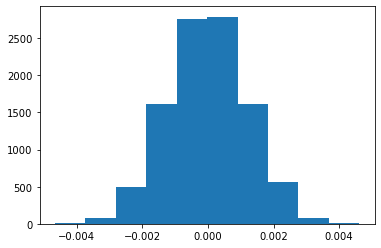

In [53]:
plt.hist(p_diffs);

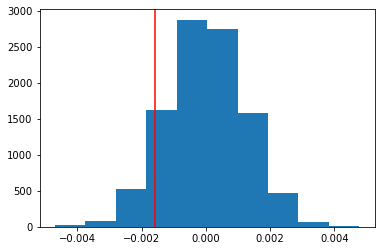

In [54]:
null_vals = np.random.normal(0.,p_diffs.std(),p_diffs.size)
plt.hist(null_vals);
plt.axvline(obs_diff, c='red');

j. What proportion of the **p_diffs** are greater than the actual difference observed in **ab_data.csv**?

In [55]:
# compute p value
(null_vals > obs_diff).mean()

0.9048

k. In words, explain what you just computed in part **j.**  What is this value called in scientific studies?  What does this value mean in terms of whether or not there is a difference between the new and old pages?



- This value called P-Value , and it is the probability of obtaining the obs_diff under the null is true or one more extreme         in favor of alternative.
- Then we found that it is equal to 0.9 and this value is greater than alpha(0.05) so we cant not reject the null.
- And that mean the conversions of the old page is still better than the conversions for the new page as the the null said.
- So based on this and also for practical reasons like money and time We MUST KEEP THE OLD PAGE.



l. We could also use a built-in to achieve similar results.  Though using the built-in might be easier to code, the above portions are a walkthrough of the ideas that are critical to correctly thinking about statistical significance. Fill in the below to calculate the number of conversions for each page, as well as the number of individuals who received each page. Let `n_old` and `n_new` refer the the number of rows associated with the old page and new pages, respectively.

In [56]:
import statsmodels.api as sm

convert_old = df2.query('group == "control" and converted == 1').count()[0]
convert_new = df2.query('group == "treatment" and converted == 1').count()[0]
n_old = df2.query('group == "control"').count()[0]
n_new = df2.query('group == "treatment"').count()[0]

m. Now use `stats.proportions_ztest` to compute your test statistic and p-value.  [Here](http://knowledgetack.com/python/statsmodels/proportions_ztest/) is a helpful link on using the built in.

In [57]:
count = np.array([convert_new,convert_old])
n_obs = np.array([n_new,n_old])
z_score, p_value = sm.stats.proportions_ztest(count , n_obs , alternative='larger')
print(z_score, p_value)

-1.3109241984234394 0.9050583127590245


n. What do the z-score and p-value you computed in the previous question mean for the conversion rates of the old and new pages?  Do they agree with the findings in parts **j.** and **k.**?

>**We found that Z-Score = -1.3 , is less than Z-alpha(0.05) which equals 1.960 and also we found that p-value is 0.9 then it is greater than Alpha(0.05), hence we fail to reject the null , and that mean the conversions of the old page is still better than the conversions of the new page as null said , so We shoul KEEP THE OLD PAGE.**

<a id='regression'></a>
### Part III - A regression approach

`1.` In this final part, you will see that the result you acheived in the previous A/B test can also be acheived by performing regression.<br><br>

a. Since each row is either a conversion or no conversion, what type of regression should you be performing in this case?

**Logistic Regression.**

b. The goal is to use **statsmodels** to fit the regression model you specified in part **a.** to see if there is a significant difference in conversion based on which page a customer receives.  However, you first need to create a column for the intercept, and create a dummy variable column for which page each user received.  Add an **intercept** column, as well as an **ab_page** column, which is 1 when an individual receives the **treatment** and 0 if **control**.

In [58]:
df2.head()

,user_id,timestamp,group,landing_page,converted
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0
1,781507,2017-01-02 13:42:15.234051,control,old_page,0
2,737319,2017-01-02 13:42:21.786186,control,old_page,0
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0


In [59]:
df2['ab_page'] = pd.get_dummies(df2['landing_page'])['new_page']
df2.head()

,user_id,timestamp,group,landing_page,converted,ab_page
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0,1
1,781507,2017-01-02 13:42:15.234051,control,old_page,0,0
2,737319,2017-01-02 13:42:21.786186,control,old_page,0,0
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0,1
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0,1


c. Use **statsmodels** to import your regression model.  Instantiate the model, and fit the model using the two columns you created in part **b.** to predict whether or not an individual converts.

In [62]:
import statsmodels.api as sm

In [66]:
df2['intercept'] = 1
log_mod = sm.Logit(df2['converted'] , df2[['intercept','ab_page']])
results = log_mod.fit()

Optimization terminated successfully.
         Current function value: 0.366118
         Iterations 6


d. Provide the summary of your model below, and use it as necessary to answer the following questions.

In [67]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290582
Method:                           MLE   Df Model:                            1
Date:                Wed, 23 Mar 2022   Pseudo R-squ.:               8.077e-06
Time:                        20:40:29   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1899
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -1.9888      0.008   -246.669      0.000      -2.005      -1.973
ab_page       -0.0150      0.011     -1.311      0.190      -0.037       0.007
==============================================================================
"""

e. What is the p-value associated with **ab_page**? Why does it differ from the value you found in **Part II**?<br><br>  **Hint**: What are the null and alternative hypotheses associated with your regression model, and how do they compare to the null and alternative hypotheses in the **Part II**?

**In Regression: P-Values are given for testing if the parameter for the intercept or the slope(ab_page) are equal to zero,       
and Null Hypothesis and alternative like this:**

**For intercept:**
$$H_0: B_{0} = 0$$


$$H_1: B_{0} \neq 0$$

**For ab_page:**

$$H_0: B_{1} = 0$$


$$H_1: B_{1} \neq 0$$

**This P-Value give a quick glimpse as to whether or not a particular variable is useful for predicting the Response,          and as we found the P-Value for the AB_PAGE is Large so we have no evidence of a relationship between ab_page and conversion so this AB_BAGE is not important anymore to predict the conversions and that mean the two pages are affecting equally on the conversions so based on that we can not depend on this variable to predict the conversions.**

f. Now, you are considering other things that might influence whether or not an individual converts.  Discuss why it is a good idea to consider other factors to add into your regression model.  Are there any disadvantages to adding additional terms into your regression model?

**I think we need more features about individuals and also make some interactions between these variables to make good predictions , this will help us to individualize the idea nicely, but take in mind that might lead to potential problems and that depends on our use for the model whether i use it to illustrate a relationship between inputs and response or i use it to make best prediction!.**

g. Now along with testing if the conversion rate changes for different pages, also add an effect based on which country a user lives. You will need to read in the **countries.csv** dataset and merge together your datasets on the approporiate rows.  [Here](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.join.html) are the docs for joining tables. 

Does it appear that country had an impact on conversion?  Don't forget to create dummy variables for these country columns - **Hint: You will need two columns for the three dummy variables.** Provide the statistical output as well as a written response to answer this question.

In [68]:
countries_df = pd.read_csv('./countries.csv')
df_new = countries_df.set_index('user_id').join(df2.set_index('user_id'), how='inner')

In [69]:
df_new.head()

,country,timestamp,group,landing_page,converted,ab_page,intercept
user_id,,,,,,,
834778,UK,2017-01-14 23:08:43.304998,control,old_page,0,0,1
928468,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,1
822059,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,1
711597,UK,2017-01-22 03:14:24.763511,control,old_page,0,0,1
710616,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,1


In [72]:
df_new.country.value_counts()

US    203619
UK     72466
CA     14499
Name: country, dtype: int64

In [76]:
### Create the necessary dummy variables
df_new[['CA','UK','US']] = pd.get_dummies(df_new['country'])
df_new = df_new.drop('CA' , axis=1)
df_new.head()

,country,timestamp,group,landing_page,converted,ab_page,intercept,UK,US
user_id,,,,,,,,,
834778,UK,2017-01-14 23:08:43.304998,control,old_page,0,0,1,1,0
928468,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,1,0,1
822059,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,1,1,0
711597,UK,2017-01-22 03:14:24.763511,control,old_page,0,0,1,1,0
710616,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,1,1,0


h. Though you have now looked at the individual factors of country and page on conversion, we would now like to look at an interaction between page and country to see if there significant effects on conversion.  Create the necessary additional columns, and fit the new model.  

Provide the summary results, and your conclusions based on the results.

In [86]:
### Fit Your Linear Model And Obtain the Results
df_new['ab_UK'] = df_new['ab_page'] * df_new['UK']
df_new['ab_US'] = df_new['ab_page'] * df_new['US']
log_mod = sm.Logit(df_new['converted'] , df_new[['intercept','ab_page','UK','US','ab_UK','ab_US']])
results = log_mod.fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.366109
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290578
Method:                           MLE   Df Model:                            5
Date:                Thu, 24 Mar 2022   Pseudo R-squ.:               3.482e-05
Time:                        01:27:20   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1920
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -2.0040      0.036    -55.008      0.000      -2.075      -1.933
ab_page       -0.0674      0.052     -1.297      0.195      -0.169       0.034
UK             0.0118      0.040      0.296      0.767      -0.066       0.090
US             0.0175      0.038      0.465      0.642      -0.056       0.091
ab_UK          0.0783      0.057      1.378      0.168      -0.033       0.190
ab_US          0.0469      0.054      0.872      0.383      -0.059       0.152
==============================================================================
"""

In [87]:
np.exp(results.params)

intercept    0.134794
ab_page      0.934776
UK           1.011854
US           1.017682
ab_UK        1.081428
ab_US        1.048001
dtype: float64

In [88]:
1/_

intercept    7.418713
ab_page      1.069775
UK           0.988285
US           0.982625
ab_UK        0.924703
ab_US        0.954198
dtype: float64

As we saw that P-Value is large in all cases so there is no evidence for the relationship between any variable and the output, even with making interactions we can not get any evidence for any variable to make good predictions about the conversions,
hence we could say that we should KEEP THE OLD PAGE and THAT WHAT WE HAVE FOUND ALSO IN THE A/B TESTING BEFORE.  

# Conclusions

- Here I wanted to decide whether to implement a new page or keep the old page to increase the conversions of our company website. 
- We first gathered data about the two pages and number of conversions for every page.
- Then we implement A/B Testing to see whether the new page make more conversions or not.
- Results from our A/B Testing said that there is no statistically significance for the new page and that mean the old page is the best or in another way the new page didn't make any develop in conversion and also we found that the old page made more conversions slightly.
- Based on that Results we should KEEP THE OLD PAGE as it is better than the new in conversions slightly and also for practical issues such as time and cost we must KEEP THE OLD PAGE.
- After that we made some regression models to see if there's evidences for the relationships between the landing page and the conversion and we found there is no evidence that there's a relationship so we can not make prediction using the landing page.
- Finally we added new features and made some interactions and also there is no evidence.
- Decision : as the old page is better for the conversions and also for saving money and effort we MUST KEEP THE OLD PAGE.
      THANKS

<a id='conclusions'></a>
## Conclusions

Congratulations on completing the project! 

### Gather Submission Materials

Once you are satisfied with the status of your Notebook, you should save it in a format that will make it easy for others to read. You can use the __File -> Download as -> HTML (.html)__ menu to save your notebook as an .html file. If you are working locally and get an error about "No module name", then open a terminal and try installing the missing module using `pip install <module_name>` (don't include the "<" or ">" or any words following a period in the module name).

You will submit both your original Notebook and an HTML or PDF copy of the Notebook for review. There is no need for you to include any data files with your submission. If you made reference to other websites, books, and other resources to help you in solving tasks in the project, make sure that you document them. It is recommended that you either add a "Resources" section in a Markdown cell at the end of the Notebook report, or you can include a `readme.txt` file documenting your sources.

### Submit the Project

When you're ready, click on the "Submit Project" button to go to the project submission page. You can submit your files as a .zip archive or you can link to a GitHub repository containing your project files. If you go with GitHub, note that your submission will be a snapshot of the linked repository at time of submission. It is recommended that you keep each project in a separate repository to avoid any potential confusion: if a reviewer gets multiple folders representing multiple projects, there might be confusion regarding what project is to be evaluated.

It can take us up to a week to grade the project, but in most cases it is much faster. You will get an email once your submission has been reviewed. If you are having any problems submitting your project or wish to check on the status of your submission, please email us at dataanalyst-project@udacity.com. In the meantime, you should feel free to continue on with your learning journey by beginning the next module in the program.